In [2]:
%pip install -r requirements.txt

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
from pathlib import Path
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge, LinearRegression
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, mean_squared_error
import statsmodels.api as sm
from statsmodels.stats.diagnostic import acorr_ljungbox, het_breuschpagan
from statsmodels.graphics.tsaplots import plot_acf


plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["axes.grid"] = True

RANDOM_STATE = 42
DATA_DIR = Path(".")

DATA_TRAIN_PATH = DATA_DIR / "data_train.csv"
TARGET_TRAIN_PATH = DATA_DIR / "target_train.csv"
DATA_TEST_PATH = DATA_DIR / "data_test_small.csv"
TARGET_TEST_PATH = DATA_DIR / "target_test_small.csv"

LAB_DELAY_MINUTES = 12.5

In [4]:
data_train_raw = pd.read_csv(DATA_TRAIN_PATH, parse_dates=["datetime"])
target_train = pd.read_csv(TARGET_TRAIN_PATH, parse_dates=["Дата"])
data_test_raw = pd.read_csv(DATA_TEST_PATH, parse_dates=["datetime"])
target_test = pd.read_csv(TARGET_TEST_PATH, parse_dates=["Дата"])

telemetry_cols = [c for c in data_train_raw.columns if c.startswith("telemetry_")]

## 2.1. Разведочный анализ данных (EDA)

In [8]:
missing_share = data_train_raw[telemetry_cols].isna().mean() * 100  # анализ пропусков в телеметрии
display(missing_share.round(2).to_frame("Пропуски, %"))

intervals = target_train["Дата"].sort_values().diff().dt.total_seconds().div(60).dropna()  # интервалы между лабораторными замерами в минутах
display(target_train["target"].describe().round(4))  # распределение целевой переменной

,"Пропуски, %"
telemetry_0,0.01
telemetry_1,0.01
telemetry_2,0.01
telemetry_3,0.01
telemetry_4,0.04
telemetry_5,0.01
telemetry_6,0.01
telemetry_7,0.01
telemetry_8,0.01
telemetry_9,0.01


count    1773.0000
mean        0.2543
std         0.0922
min         0.0000
25%         0.1753
50%         0.2474
75%         0.3144
max         0.7165
Name: target, dtype: float64

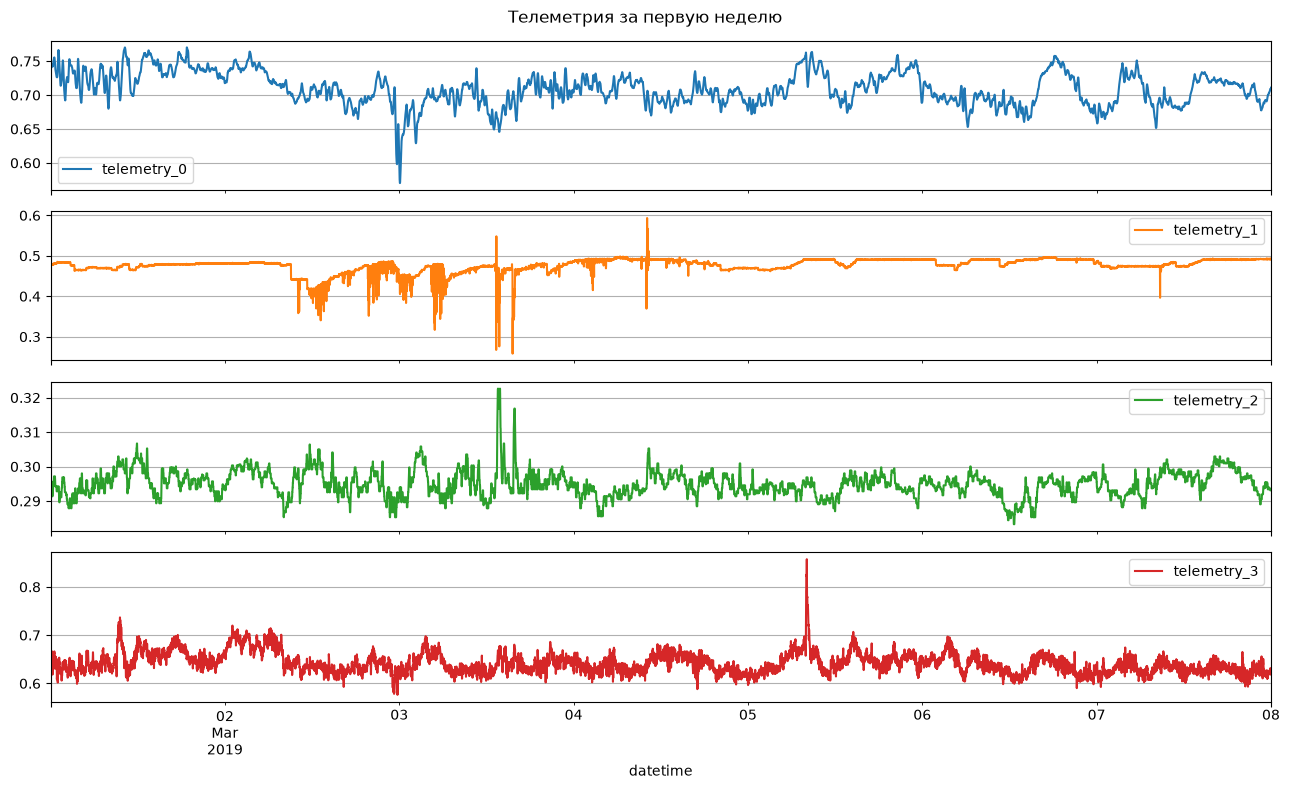

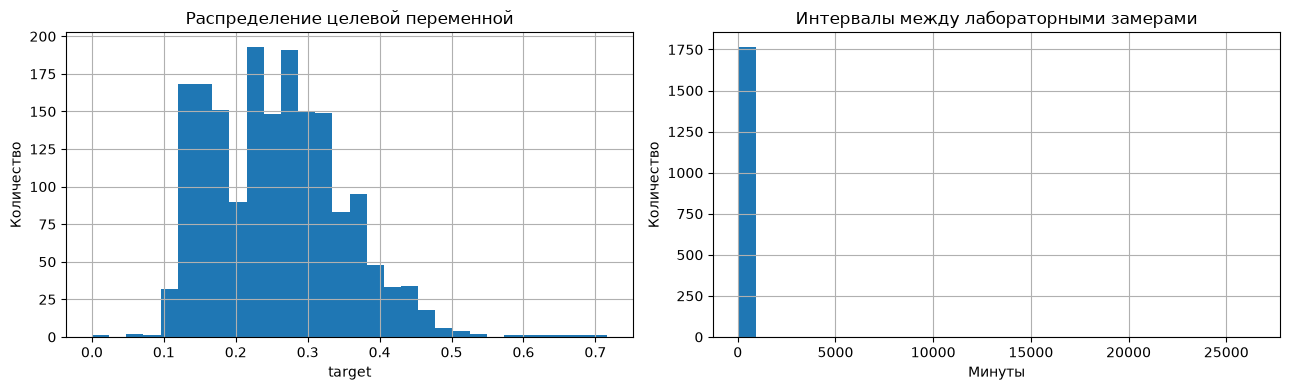

In [9]:
# динамика первых четырех показателей за первую неделю
plot_data = data_train_raw.sort_values("datetime").drop_duplicates("datetime").set_index("datetime")
plot_data[telemetry_cols[:4]].loc[
    plot_data.index.min(): plot_data.index.min() + pd.Timedelta(days=7)
].plot(subplots=True, figsize=(13, 8), title="Телеметрия за первую неделю")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
target_train["target"].hist(bins=30, ax=axes[0])
axes[0].set_title("Распределение целевой переменной")
axes[0].set_xlabel("target")
axes[0].set_ylabel("Количество")
intervals.hist(bins=30, ax=axes[1])
axes[1].set_title("Интервалы между лабораторными замерами")
axes[1].set_xlabel("Минуты")
axes[1].set_ylabel("Количество")
plt.tight_layout()
plt.show()

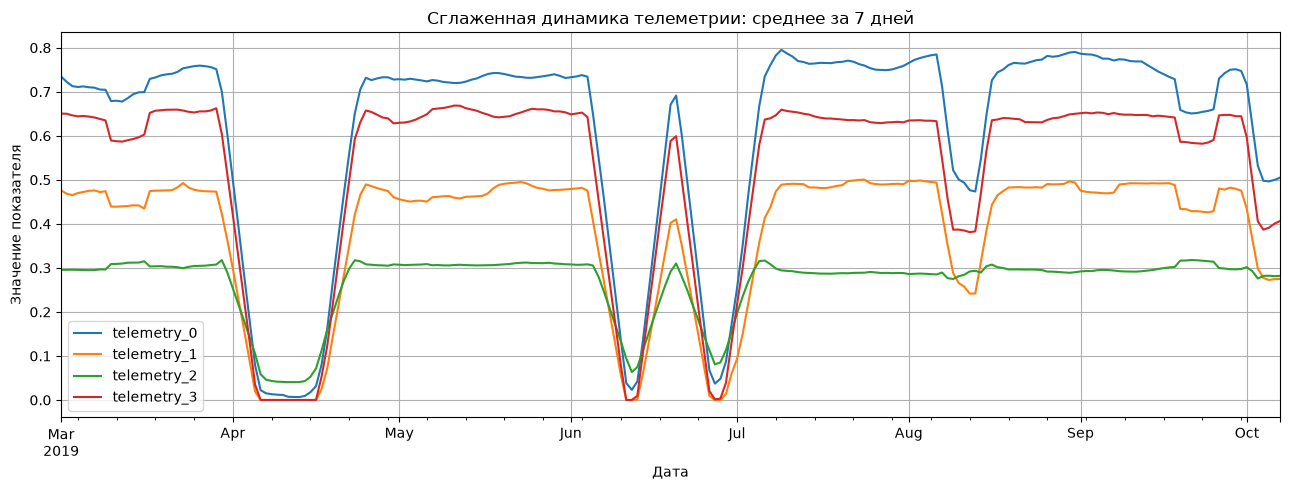

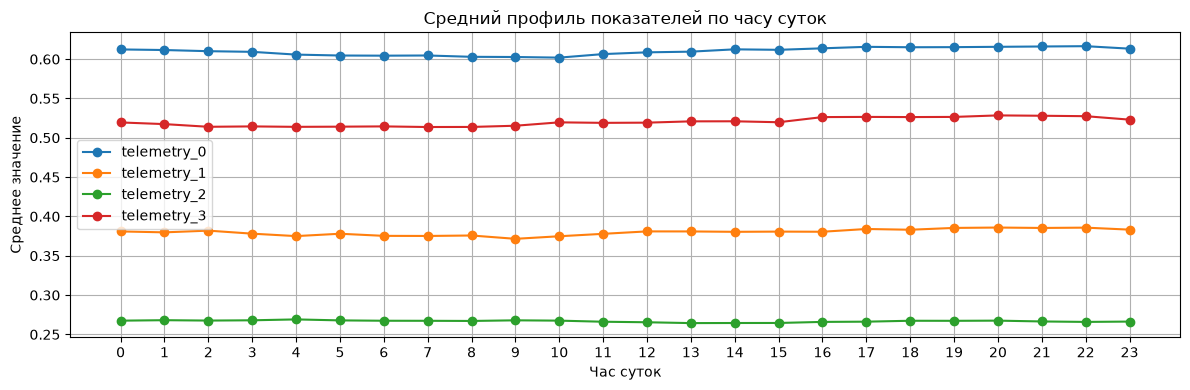

,Показатель,"Доля за границами IQR, %",Минимум,Максимум
1,telemetry_1,22.571,0.000,0.611
6,telemetry_6,22.081,0.000,1.000
7,telemetry_7,22.009,0.021,1.000
4,telemetry_4,21.393,0.000,1.000
0,telemetry_0,21.300,0.003,1.000
2,telemetry_2,21.276,0.032,1.000
3,telemetry_3,20.610,0.000,1.000
5,telemetry_5,17.996,0.000,1.000
14,telemetry_14,1.287,0.102,0.909
8,telemetry_8,1.255,0.344,1.000


In [10]:
# долгосрочный тренд и суточная сезонность
daily_mean = plot_data[telemetry_cols[:4]].resample("1D").mean()
daily_mean.rolling(7, min_periods=1).mean().plot(figsize=(13, 5))
plt.title("Сглаженная динамика телеметрии: среднее за 7 дней")
plt.xlabel("Дата")
plt.ylabel("Значение показателя")
plt.tight_layout()
plt.show()

hour_profile = plot_data[telemetry_cols[:4]].groupby(plot_data.index.hour).mean()
hour_profile.plot(marker="o", figsize=(12, 4))
plt.title("Средний профиль показателей по часу суток")
plt.xlabel("Час суток")
plt.ylabel("Среднее значение")
plt.xticks(range(24))
plt.tight_layout()
plt.show()

# потенциальны выбросы
outlier_rows = []
for col in telemetry_cols:
    values = data_train_raw[col].dropna()
    q1, q3 = values.quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    outlier_rows.append({
        "Показатель": col,
        "Доля за границами IQR, %": ((values < low) | (values > high)).mean() * 100,
        "Минимум": values.min(),
        "Максимум": values.max(),
    })

display(pd.DataFrame(outlier_rows).sort_values("Доля за границами IQR, %", ascending=False).round(3))

`Дата` считается временем получения результата анализа. Предполагаем, что проба была отобрана за 12,5 минуты до этого. Для прогноза используем последнюю доступную запись телеметрии до момента отбора пробы, чтобы исключить будущие данные.

In [12]:
# корреляции для нескольких вариантов временного сдвига
lag_rows = []
for delay in [0, 10, 12.5, 15]:
    sample_times = target_train["Дата"] - pd.to_timedelta(delay, unit="m")
    left = pd.DataFrame({"sample_time": sample_times, "target": target_train["target"]})
    right = data_train_raw[["datetime"] + telemetry_cols].copy()
    right = right.groupby("datetime", as_index=False)[telemetry_cols].mean().sort_values("datetime")
    left["sample_time"] = pd.to_datetime(left["sample_time"]).astype("datetime64[ns]")
    right["datetime"] = pd.to_datetime(right["datetime"]).astype("datetime64[ns]")
    joined = pd.merge_asof(
        left.sort_values("sample_time"),
        right,
        left_on="sample_time",
        right_on="datetime",
        direction="backward",
        tolerance=pd.Timedelta("1min"),
    )
    for col in telemetry_cols:
        pair = joined[[col, "target"]].dropna()
        corr = pair[col].corr(pair["target"]) if len(pair) >= 30 else np.nan
        lag_rows.append({"Задержка, мин": delay, "Показатель": col, "Корреляция": corr, "Число точек": len(pair)})

lag_corr = pd.DataFrame(lag_rows)
print("Для корреляций использовано не менее 30 наблюдений.")
display(lag_corr.pivot(index="Показатель", columns="Задержка, мин", values="Корреляция").round(3))

Для корреляций использовано не менее 30 наблюдений.


"Задержка, мин",0.0,10.0,12.5,15.0
Показатель,,,,
telemetry_0,-0.187,-0.183,-0.179,-0.177
telemetry_1,-0.044,-0.040,-0.031,-0.044
telemetry_10,-0.069,-0.071,-0.070,-0.072
telemetry_11,-0.087,-0.090,-0.089,-0.089
telemetry_12,NaN,NaN,NaN,NaN
telemetry_13,NaN,NaN,NaN,NaN
telemetry_14,NaN,NaN,NaN,NaN
telemetry_15,NaN,NaN,NaN,NaN
telemetry_2,-0.003,-0.011,-0.012,-0.011


**Выводы по EDA.** Телеметрия записывается примерно раз в минуту, лабораторные замеры - нерегулярно, с интервалами около двух часов. Повторяющиеся временные метки телеметрии требуют агрегации. Четыре показателя (telemetry_12–15) практически не содержат данных. Корреляции остальных показателей с целевой переменной слабые; изменение задержки с 0 до 15 минут существенно на них не влияет.

## 2.2. Инжиниринг признаков для временных рядов

Повторные значения времени усредняются. Затем формируется минутная временная сетка. Для редких датчиков последнее известное значение переносится максимум на 119 минут (почти до следующего ожидаемого двухчасового измерения). Дополнительно сохраняется давность последнего измерения.

Для каждого показателя рассчитываются текущее значение, лаги, скользящие статистики и разности. Все окна используют только текущие и прошлые данные.

In [14]:
# объединяем обучающую и тестовую телеметрию для покрытия всех меток
all_telemetry_raw = pd.concat([data_train_raw, data_test_raw], ignore_index=True)
all_telemetry_raw["datetime"] = pd.to_datetime(all_telemetry_raw["datetime"])

# если в одну минуту было несколько записей, берём среднее
telemetry = (
    all_telemetry_raw
    .groupby("datetime")[telemetry_cols]
    .mean()
    .sort_index()
)

# восстанавливаем непрерывную минутную сетку
minute_index = pd.date_range(telemetry.index.min(), telemetry.index.max(), freq="1min")
telemetry = telemetry.reindex(minute_index)
telemetry.index.name = "datetime"

# редкие показатели измеряются примерно раз в два часа
sparse_cols = ["telemetry_12", "telemetry_13", "telemetry_14", "telemetry_15"]
for col in sparse_cols:
    last_time = pd.Series(telemetry.index, index=telemetry.index).where(telemetry[col].notna()).ffill()
    age = (pd.Series(telemetry.index, index=telemetry.index) - last_time).dt.total_seconds() / 60
    telemetry[f"{col}_age_min"] = age.astype("float32")
    telemetry[col] = telemetry[col].ffill(limit=119)

print("Размер минутной сетки:", telemetry.shape)
print("Период:", telemetry.index.min(), "—", telemetry.index.max())
print("Пропуски после ограниченного переноса:")
display((telemetry[telemetry_cols].isna().mean() * 100).round(2).to_frame("Пропуски, %"))

Размер минутной сетки: (357745, 20)
Период: 2019-03-01 00:01:00 — 2019-11-04 10:25:00
Пропуски после ограниченного переноса:


,"Пропуски, %"
telemetry_0,0.01
telemetry_1,0.00
telemetry_2,0.00
telemetry_3,0.00
telemetry_4,0.04
telemetry_5,0.01
telemetry_6,0.00
telemetry_7,0.00
telemetry_8,0.00
telemetry_9,0.00


In [19]:
# создаем признаки из текущих и прошлых значений телеметрии
def create_time_features(frame, columns):
    features = {}

    for col in columns:
        series = frame[col].astype("float32")
        features[f"{col}_current"] = series
        for lag in [5, 15]:
            features[f"{col}_lag_{lag}"] = series.shift(lag)
            features[f"{col}_diff_{lag}"] = series - series.shift(lag)
        for window in [15, 60]:
            rolling = series.rolling(window=window, min_periods=max(2, window // 2))
            features[f"{col}_mean_{window}"] = rolling.mean()
            features[f"{col}_std_{window}"] = rolling.std()
            features[f"{col}_min_{window}"] = rolling.min()
            features[f"{col}_max_{window}"] = rolling.max()

    result = pd.DataFrame(features, index=frame.index)

    for col in sparse_cols:
        result[f"{col}_age_min"] = frame[f"{col}_age_min"]

    return result.astype("float32")


features = create_time_features(telemetry, telemetry_cols)
feature_cols = features.columns.tolist()
current_feature_cols = [f"{c}_current" for c in telemetry_cols]

print("Количество временных признаков:", len(feature_cols))
print("Первые признаки:", feature_cols[:12])

Количество временных признаков: 212
Первые признаки: ['telemetry_0_current', 'telemetry_0_lag_5', 'telemetry_0_diff_5', 'telemetry_0_lag_15', 'telemetry_0_diff_15', 'telemetry_0_mean_15', 'telemetry_0_std_15', 'telemetry_0_min_15', 'telemetry_0_max_15', 'telemetry_0_mean_60', 'telemetry_0_std_60', 'telemetry_0_min_60']


In [24]:
# привязывает лабораторную метку к последней доступной минуте телеметрии
def align_target(target, features_frame, delay):
    target = target.copy()
    target["sample_time"] = (
        pd.to_datetime(target["Дата"]) - pd.Timedelta(minutes=delay)
    ).astype("datetime64[ns]")
    target = target.sort_values("sample_time")
    feature_data = features_frame.reset_index().rename(columns={features_frame.index.name: "feature_time"})
    feature_data["feature_time"] = pd.to_datetime(feature_data["feature_time"]).astype("datetime64[ns]")
    feature_data = feature_data.sort_values("feature_time")

    aligned = pd.merge_asof(
        target,
        feature_data,
        left_on="sample_time",
        right_on="feature_time",
        direction="backward",
        tolerance=pd.Timedelta("1min"),
    )

    return aligned

train_aligned = align_target(target_train, features, LAB_DELAY_MINUTES)
test_aligned = align_target(target_test, features, LAB_DELAY_MINUTES)
train_aligned = train_aligned.dropna(subset=feature_cols, how="all").reset_index(drop=True)
test_aligned = test_aligned.dropna(subset=feature_cols, how="all").reset_index(drop=True)

print("Обучающих синхронизированных замеров:", len(train_aligned))
print("Тестовых синхронизированных замеров:", len(test_aligned))

display(train_aligned[["Дата", "sample_time", "feature_time", "target"]].head())

Обучающих синхронизированных замеров: 1773
Тестовых синхронизированных замеров: 318


,Дата,sample_time,feature_time,target
0,2019-03-13 17:00:00,2019-03-13 16:47:30,2019-03-13 16:47:00,0.123711
1,2019-03-13 21:00:00,2019-03-13 20:47:30,2019-03-13 20:47:00,0.319588
2,2019-03-14 01:00:00,2019-03-14 00:47:30,2019-03-14 00:47:00,0.255155
3,2019-03-14 05:00:00,2019-03-14 04:47:30,2019-03-14 04:47:00,0.319588
4,2019-03-14 09:00:00,2019-03-14 08:47:30,2019-03-14 08:47:00,0.159794


**Выводы по инжинирингу признаков.** Сформировано 1773 обучающих и 318 тестовых синхронизированных замеров. Созданы признаки текущих значений, временных лагов, изменений и статистик за 15 и 60 минут. Для редких показателей учитывается давность измерения. PCA не применялся, чтобы сохранить интерпретируемость признаков. Пропуски будут заполнены медианами, рассчитанными на обучающей выборке.

## 2.3. Построение прогнозных моделей

Сравним четыре модели:

1. **Линейная регрессия (OLS)** - простой интерпретируемый базовый вариант на текущих значениях датчиков.
2. **Ridge** - линейная модель с регуляризацией, полезная при коррелирующих лагах и скользящих статистиках.
3. **Random Forest** - ансамбль деревьев, способный находить нелинейные зависимости.
4. **HistGradientBoosting** - градиентный бустинг по деревьям, подходящий для табличных признаков.

In [25]:
# 80% обучение, 20% валидация
train_aligned = train_aligned.sort_values("sample_time").reset_index(drop=True)
split_index = int(len(train_aligned) * 0.8)

train_part = train_aligned.iloc[:split_index].copy()
valid_part = train_aligned.iloc[split_index:].copy()

X_train = train_part[feature_cols]
y_train = train_part["target"]
X_valid = valid_part[feature_cols]
y_valid = valid_part["target"]

X_train_current = train_part[current_feature_cols]
X_valid_current = valid_part[current_feature_cols]

print("Обучающая часть:", X_train.shape, "", y_train.shape)
print("Валидационная часть:", X_valid.shape, "", y_valid.shape)
print("Граница разделения:", valid_part["sample_time"].min())

Обучающая часть: (1418, 212)  (1418,)
Валидационная часть: (355, 212)  (355,)
Граница разделения: 2019-08-24 02:47:30


In [26]:
models = {
    "OLS": (
        Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
            ("model", LinearRegression()),
        ]),
        current_feature_cols,
    ),
    "Ridge": (
        Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
            ("model", Ridge(alpha=10.0)),
        ]),
        feature_cols,
    ),
    "Random Forest": (
        Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("model", RandomForestRegressor(
                n_estimators=250,
                max_depth=12,
                min_samples_leaf=3,
                max_features="sqrt",
                random_state=RANDOM_STATE,
                n_jobs=-1,
            )),
        ]),
        feature_cols,
    ),
    "HistGradientBoosting": (
        Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("model", HistGradientBoostingRegressor(
                max_iter=250,
                learning_rate=0.05,
                max_leaf_nodes=15,
                l2_regularization=1.0,
                random_state=RANDOM_STATE,
            )),
        ]),
        feature_cols,
    ),
}

fitted_models = {}
validation_predictions = {}
model_rows = []

for name, (pipeline, used_cols) in models.items():
    X_tr = train_part[used_cols]
    X_va = valid_part[used_cols]

    start = time.perf_counter()
    pipeline.fit(X_tr, y_train)
    fit_seconds = time.perf_counter() - start

    start = time.perf_counter()
    predictions = pipeline.predict(X_va)
    predict_seconds = time.perf_counter() - start

    fitted_models[name] = pipeline
    validation_predictions[name] = predictions

    model_rows.append({
        "Модель": name,
        "MAE": mean_absolute_error(y_valid, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_valid, predictions)),
        "Время обучения, сек": fit_seconds,
        "Время прогноза, сек": predict_seconds,
    })

# всегда предсказываем медиану обучающей части
baseline_prediction = np.full(len(y_valid), y_train.median())
validation_predictions["Median baseline"] = baseline_prediction
model_rows.append({
    "Модель": "Median baseline",
    "MAE": mean_absolute_error(y_valid, baseline_prediction),
    "RMSE": np.sqrt(mean_squared_error(y_valid, baseline_prediction)),
    "Время обучения, сек": 0.0,
    "Время прогноза, сек": 0.0,
})

model_comparison = pd.DataFrame(model_rows).sort_values("MAE").reset_index(drop=True)
display(model_comparison.round(5))

,Модель,MAE,RMSE,"Время обучения, сек","Время прогноза, сек"
0,OLS,0.06516,0.08046,0.05757,0.00120
1,HistGradientBoosting,0.06592,0.08336,3.33822,0.00621
2,Random Forest,0.06626,0.08223,0.27282,0.04236
3,Median baseline,0.07038,0.08432,0.00000,0.00000
4,Ridge,0.07449,0.09376,0.02280,0.00242


### Информационные критерии для статистической модели

AIC и BIC корректно интерпретируются для статистических моделей с заданной функцией правдоподобия. Поэтому рассчитаем их для OLS на обучающей части и 16 текущих значениях телеметрии. Для Random Forest и градиентного бустинга эти критерии в стандартном виде не используются.

In [27]:
# AIC и BIC считаются для OLS на обучающей части
ols_imputer = SimpleImputer(strategy="median")
X_ols_train = ols_imputer.fit_transform(X_train_current)
X_ols_train = sm.add_constant(X_ols_train, has_constant="add")
ols_stats = sm.OLS(y_train.to_numpy(), X_ols_train).fit()

print(f"OLS AIC: {ols_stats.aic:.2f}")
print(f"OLS BIC: {ols_stats.bic:.2f}")
print(f"OLS R-squared: {ols_stats.rsquared:.4f}")

OLS AIC: -2979.05
OLS BIC: -2889.68
OLS R-squared: 0.2153


**Какие модели здесь не подходят как основной вариант.** Чистая ARIMA использует в основном историю одной целевой последовательности и не учитывает напрямую 16 каналов телеметрии. Кроме того, лабораторные метки нерегулярны и поступают редко. LSTM и Transformer требуют более сложной подготовки последовательностей и большого числа размеченных примеров; здесь доступно около 1,8 тыс. лабораторных меток, поэтому риск переобучения высок. Случайное разбиение также не подходит, так как смешивает прошлые и будущие режимы печи.

## 2.3. Оценка качества моделей

Используем MAE, RMSE, MAPE и WAPE. MAPE рассчитывается без точек, где фактическое значение не превышает 0,01 по модулю. Дополнительно оценим точность направления изменения между соседними лабораторными замерами.

In [28]:
def regression_metrics(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)

    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    nonzero = np.abs(y_true) > 0.01
    mape = np.mean(np.abs((y_true[nonzero] - y_pred[nonzero]) / y_true[nonzero])) * 100
    wape = np.sum(np.abs(y_true - y_pred)) / np.sum(np.abs(y_true)) * 100

    if len(y_true) > 1:
        actual_delta = np.diff(y_true)
        predicted_delta = np.diff(y_pred)
        moving = np.abs(actual_delta) > 1e-4
        if moving.any():
            actual_direction = np.sign(actual_delta[moving])
            predicted_direction = np.sign(predicted_delta[moving])
            direction_accuracy = np.mean(actual_direction == predicted_direction) * 100
        else:
            direction_accuracy = np.nan
    else:
        direction_accuracy = np.nan

    return {
        "MAE": mae,
        "RMSE": rmse,
        "MAPE, %": mape,
        "WAPE, %": wape,
        "Точность направления, %": direction_accuracy,
    }

validation_metrics = []
for name, predictions in validation_predictions.items():
    row = {"Модель": name}
    row.update(regression_metrics(y_valid, predictions))
    validation_metrics.append(row)

validation_metrics = pd.DataFrame(validation_metrics).sort_values("MAE")
display(validation_metrics.round(4))

best_name = validation_metrics.loc[validation_metrics["Модель"] != "Median baseline"].sort_values("MAE").iloc[0]["Модель"]
print("Лучшая модель по MAE на временной валидации:", best_name)

baseline_mae = validation_metrics.loc[validation_metrics["Модель"] == "Median baseline", "MAE"].iloc[0]
best_mae = validation_metrics.loc[validation_metrics["Модель"] == best_name, "MAE"].iloc[0]
print(f"MAE базового прогноза: {baseline_mae:.5f}")
print(f"MAE выбранной модели: {best_mae:.5f}")
print(f"Улучшение относительно базового прогноза: {(1 - best_mae / baseline_mae) * 100:.1f}%")

,Модель,MAE,RMSE,"MAPE, %","WAPE, %","Точность направления, %"
0,OLS,0.0652,0.0805,36.6677,28.8463,59.7015
3,HistGradientBoosting,0.0659,0.0834,36.0448,29.1825,54.9254
2,Random Forest,0.0663,0.0822,37.1782,29.3309,57.3134
4,Median baseline,0.0704,0.0843,39.9361,31.1538,0.0000
1,Ridge,0.0745,0.0938,41.6783,32.9754,58.8060


Лучшая модель по MAE на временной валидации: OLS
MAE базового прогноза: 0.07038
MAE выбранной модели: 0.06516
Улучшение относительно базового прогноза: 7.4%


### Важность признаков

Для лучшей модели используем permutation importance на валидационной части. Метод показывает, насколько ухудшается качество, если перемешать значения одного признака.

,Признак,Важность,Стандартное отклонение
0,telemetry_0_current,0.00267,0.00044
9,telemetry_9_current,0.00258,0.00025
12,telemetry_12_current,0.00250,0.00025
5,telemetry_5_current,0.00245,0.00051
6,telemetry_6_current,0.00196,0.00036
7,telemetry_7_current,0.00185,0.00085
2,telemetry_2_current,0.00169,0.00040
15,telemetry_15_current,0.00137,0.00089
1,telemetry_1_current,0.00083,0.00056
14,telemetry_14_current,0.00069,0.00049


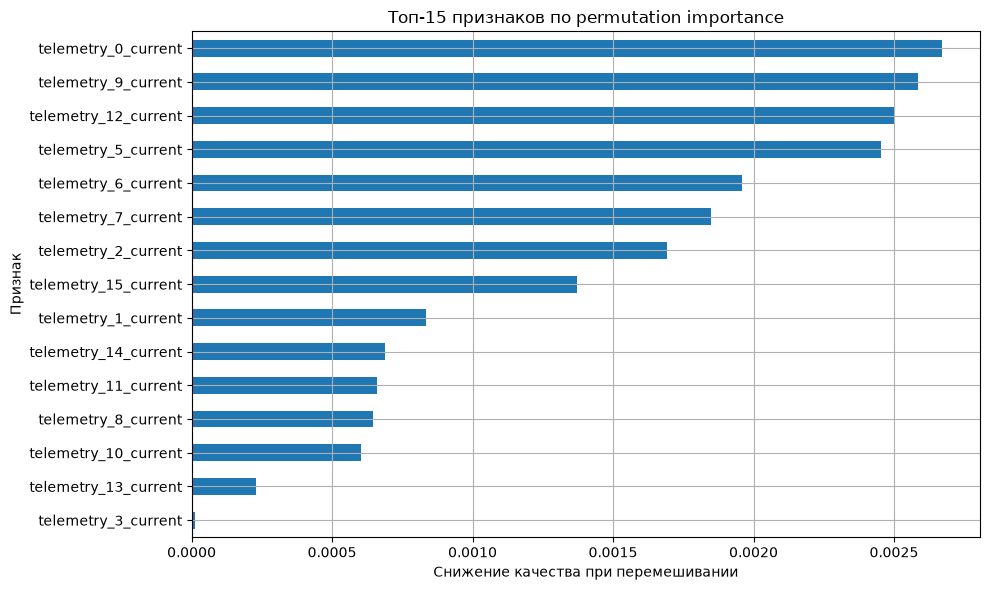

In [29]:
best_pipeline = fitted_models[best_name]
best_feature_cols = models[best_name][1]

importance = permutation_importance(
    best_pipeline,
    X_valid[best_feature_cols],
    y_valid,
    scoring="neg_mean_absolute_error",
    n_repeats=5,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

importance_table = pd.DataFrame({
    "Признак": best_feature_cols,
    "Важность": importance.importances_mean,
    "Стандартное отклонение": importance.importances_std,
}).sort_values("Важность", ascending=False)

display(importance_table.head(15).round(5))

importance_table.head(15).sort_values("Важность").plot(
    x="Признак", y="Важность", kind="barh", legend=False, figsize=(10, 6)
)
plt.title("Топ-15 признаков по permutation importance")
plt.xlabel("Снижение качества при перемешивании")
plt.ylabel("Признак")
plt.tight_layout()
plt.show()

### Анализ остатков

Проверим нормальность распределения остатков, их автокорреляцию и наличие гетероскедастичности.

Shapiro-Wilk: statistic=0.9919, p-value=0.04875


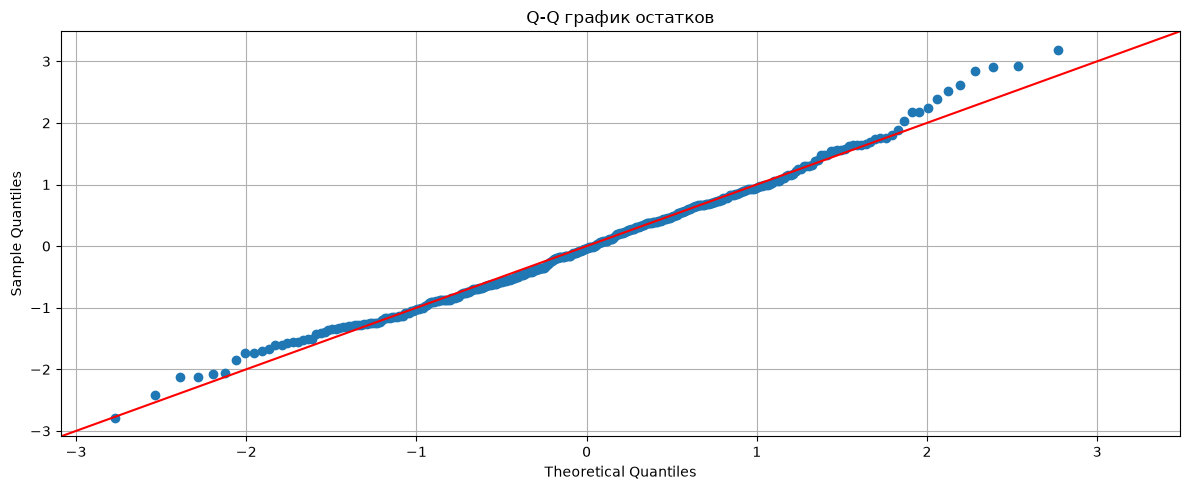

Тест Ljung-Box:


,lb_stat,lb_pvalue
10,126.429414,2.495589e-22


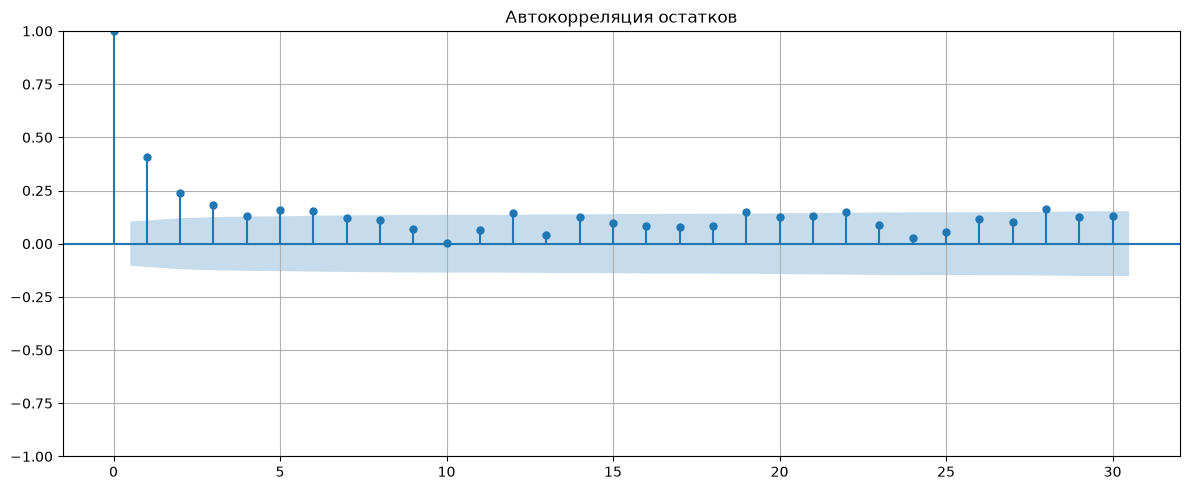

Breusch-Pagan: LM p-value=1.128e-08, F p-value=5.619e-09

Интерпретация тестов при уровне значимости 5%:
Остатки не выглядят нормально распределёнными.
В остатках есть автокорреляция.
Есть признаки гетероскедастичности.


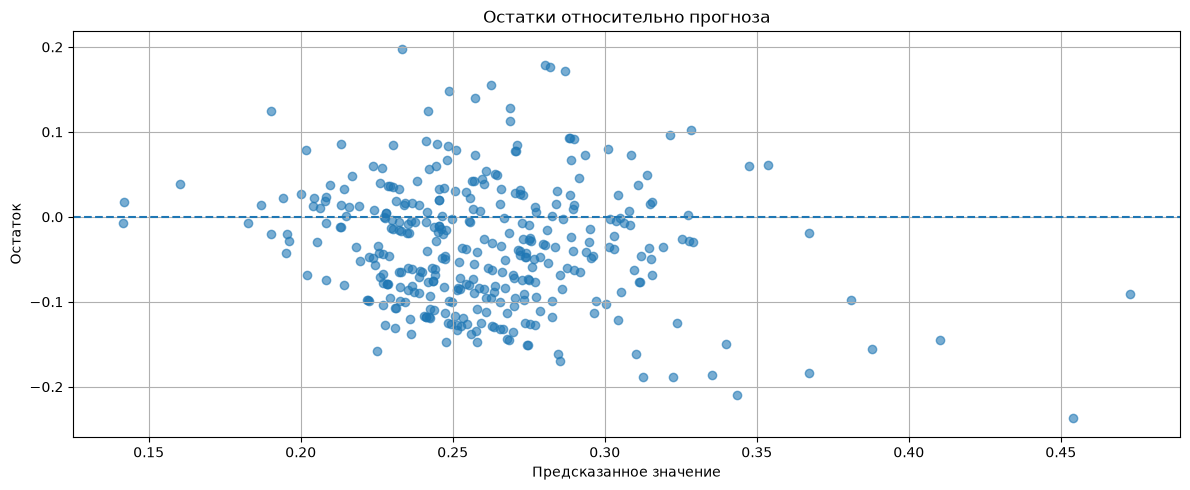

In [30]:
valid_predictions = validation_predictions[best_name]
residuals = np.asarray(y_valid) - np.asarray(valid_predictions)

# тест Шапиро-Уилка и график Q-Q
shapiro_stat, shapiro_p = stats.shapiro(residuals)
print(f"Shapiro-Wilk: statistic={shapiro_stat:.4f}, p-value={shapiro_p:.4g}")

sm.qqplot(residuals, line="45", fit=True)
plt.title("Q-Q график остатков")
plt.tight_layout()
plt.show()

# автокорреляция остатков
acf_lags = min(10, max(1, len(residuals) // 5))
ljung_box = acorr_ljungbox(residuals, lags=[acf_lags], return_df=True)
print("Тест Ljung-Box:")
display(ljung_box)

plot_acf(residuals, lags=min(30, len(residuals) - 1))
plt.title("Автокорреляция остатков")
plt.tight_layout()
plt.show()

# тест Бреуша-Пагана
bp_exog = sm.add_constant(np.asarray(valid_predictions), has_constant="add")
bp_lm, bp_lm_p, bp_f, bp_f_p = het_breuschpagan(residuals, bp_exog)
print(f"Breusch-Pagan: LM p-value={bp_lm_p:.4g}, F p-value={bp_f_p:.4g}")

print("\nИнтерпретация тестов при уровне значимости 5%:")
print("Остатки не выглядят нормально распределёнными." if shapiro_p < 0.05 else "Нет оснований отвергнуть нормальность остатков.")
ljung_p = float(ljung_box["lb_pvalue"].iloc[0])
print("В остатках есть автокорреляция." if ljung_p < 0.05 else "Значимой автокорреляции не обнаружено.")
print("Есть признаки гетероскедастичности." if bp_lm_p < 0.05 else "Признаков гетероскедастичности не обнаружено.")

plt.scatter(valid_predictions, residuals, alpha=0.6)
plt.axhline(0, linestyle="--")
plt.title("Остатки относительно прогноза")
plt.xlabel("Предсказанное значение")
plt.ylabel("Остаток")
plt.tight_layout()
plt.show()

### Прогноз на тестовом наборе

Выбранную модель переобучим на всех обучающих лабораторных замерах и оценим на `target_test_small.csv`.

In [33]:
# переобучаем лучшую модель на всех обучающих метках
final_model = models[best_name][0]
final_features = models[best_name][1]
final_model.fit(train_aligned[final_features], train_aligned["target"])

test_predictions = final_model.predict(test_aligned[final_features])
test_results = test_aligned[["Дата", "sample_time", "target"]].copy()
test_results["prediction"] = test_predictions
test_results["error"] = test_results["target"] - test_results["prediction"]

test_metrics = regression_metrics(test_results["target"], test_results["prediction"])
print("Метрики на тестовом наборе:")
display(pd.Series(test_metrics, name="Значение").to_frame().round(4))

Метрики на тестовом наборе:


,Значение
MAE,0.0626
RMSE,0.0770
"MAPE, %",35.6555
"WAPE, %",29.8459
"Точность направления, %",58.4718


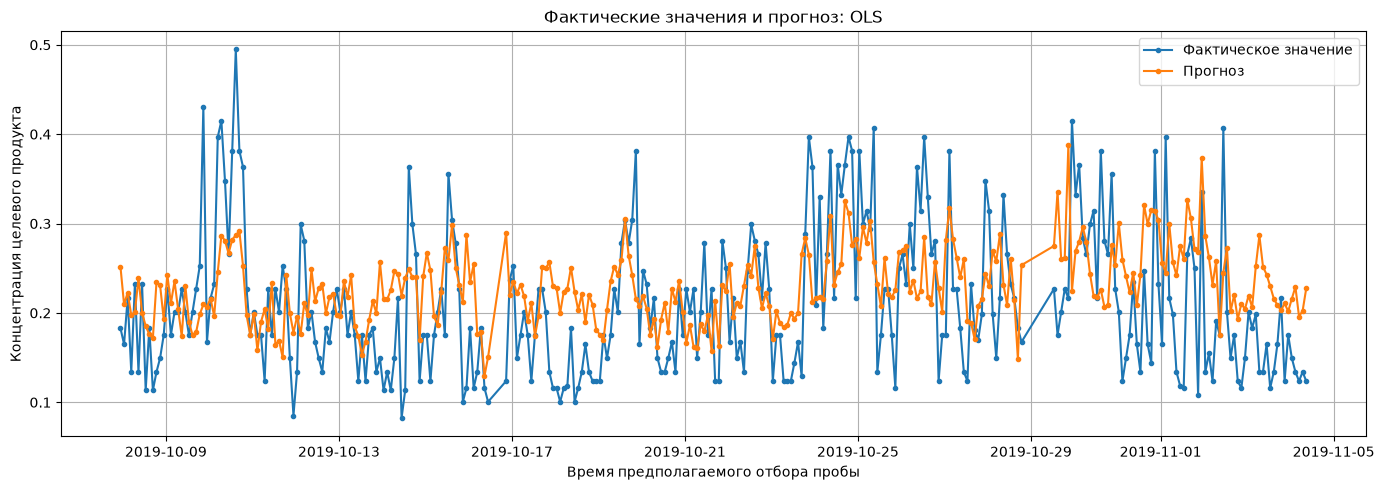

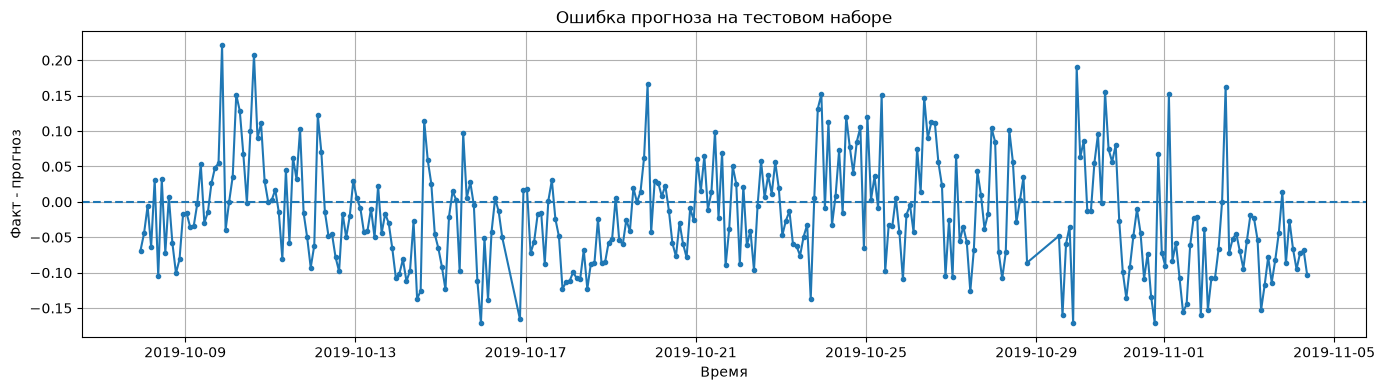

In [34]:
plt.figure(figsize=(14, 5))
plt.plot(test_results["sample_time"], test_results["target"], label="Фактическое значение", marker="o", markersize=3)
plt.plot(test_results["sample_time"], test_results["prediction"], label="Прогноз", marker="o", markersize=3)
plt.title(f"Фактические значения и прогноз: {best_name}")
plt.xlabel("Время предполагаемого отбора пробы")
plt.ylabel("Концентрация целевого продукта")
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(14, 4))
plt.plot(test_results["sample_time"], test_results["error"], marker="o", markersize=3)
plt.axhline(0, linestyle="--")
plt.title("Ошибка прогноза на тестовом наборе")
plt.xlabel("Время")
plt.ylabel("Факт - прогноз")
plt.tight_layout()
plt.show()

**Выводы по оценке качества.** На тестовой выборке OLS воспроизводит общий уровень показателя, но сглаживает резкие колебания и не всегда улавливает пики и спады. Ошибки прогноза достигают примерно от -0,17 до 0,22 и имеют участки систематического смещения. Модель не полностью описывает динамику процесса.

## 2.4. Документирование и интерпретация

В работе сравнены две линейные модели (OLS и Ridge) и два ансамблевых метода (Random Forest и HistGradientBoosting). Наименьшую MAE показала OLS (0,0652). Пермутационная важность использована для оценки вклада признаков в точность прогноза.

Поскольку физический смысл каналов телеметрии не указан, определить конкретные технологические параметры датчиков невозможно. Важность признаков отражает их статистический вклад в прогноз, но не доказывает причинно-следственную связь.

In [36]:
print(f"Использованная задержка лабораторного результата: {LAB_DELAY_MINUTES} мин")
print(f"Количество признаков: {len(feature_cols)}")
print(f"Выбранная модель: {best_name}")
print(f"Валидационный MAE: {validation_metrics.loc[validation_metrics['Модель'] == best_name, 'MAE'].iloc[0]:.5f}")
print(f"Тестовый MAE: {test_metrics['MAE']:.5f}")
print(f"Тестовый RMSE: {test_metrics['RMSE']:.5f}")
print(f"Тестовый WAPE: {test_metrics['WAPE, %']:.2f}%")

Использованная задержка лабораторного результата: 12.5 мин
Количество признаков: 212
Выбранная модель: OLS
Валидационный MAE: 0.06516
Тестовый MAE: 0.06259
Тестовый RMSE: 0.07697
Тестовый WAPE: 29.85%


## Общий вывод

Построен пайплайн виртуального датчика: телеметрия синхронизируется с лабораторными замерами, формируются временные признаки и обучаются четыре регрессионные модели. По результатам сравнения наилучшую точность показала OLS (MAE = 0,0652 на валидации). При этом модель не полностью улавливает резкие колебания целевого показателя. Для дальнейшего практического применения модели необходимо установить физический смысл каналов телеметрии и проверить устойчивость модели на более длительном периоде.